# Syllable acoustics across heliox renditions: Fig. 5 F-H

Reads one file, `vae_latent_data.pkl`, written by the data notebook. It holds the saved
results of the VAE analysis; this notebook draws them and collects the numbers.

| Panel | What it shows | Output file |
|---|---|---|
| Fig. 5F | One zebra finch syllable: each heliox rendition's position between the heliox and regular air centroids, in recording order | `zf_heliox_to_regair_projection.png` |
| Fig. 5G | Directional drift through latent space under heliox, by species | `latent_syllable_displacement_heliox.png` |
| Fig. 5H | Rate of movement toward the regular air centroid, by species | `heliox_shift_to_regair.png` |

**Run order:** top to bottom.

In [2]:
# Cell 1: settings and data
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from scipy import stats

# Paths relative to the repository, so a fresh clone runs without edits (from the repo folder or
# from notebooks/). To use other copies, e.g. on the cluster: export HELIOX_DATA_DIR=/path/to/data/derived
REPO = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DATA_DIR = os.environ.get('HELIOX_DATA_DIR', os.path.join(REPO, 'data'))
OUT_DIR = os.environ.get('HELIOX_FIG_DIR', os.path.join(REPO, 'figures'))
DATA_PATH = os.path.join(DATA_DIR, 'vae_latent_data.pkl')
os.makedirs(OUT_DIR, exist_ok=True)

with open(DATA_PATH, 'rb') as f:
    T = pickle.load(f)
print(f"data built {T['meta']['created']}")
for name, df in T.items():
    if name != 'meta':
        print(f'  {name:32s} {len(df):>5d} rows')

CONDITION_COLORS = {'regair': '#9663d8', 'heliox': '#82c564'}
SPECIES = ['zebra finch', 'starling']
STATS = []          # every number on the panels, collected for Cell 6


def save(name):
    plt.savefig(os.path.join(OUT_DIR, name), format='png', bbox_inches='tight', dpi=300)

data built 2026-10-11T12:10:57
  strip_zf_r11g11_syl5_latents       156 rows
  strip_zf_r11g11_syl5_meta            1 rows
  disp_heliox_birds                   11 rows
  disp_heliox_stats                    1 rows
  gap_zebra_finch_pairs               66 rows
  gap_zebra_finch_pooled               1 rows
  gap_starling_pairs                  36 rows
  gap_starling_pooled                  1 rows


## Fig. 5F: one example syllable

The axis runs from the heliox centroid (0) to the regular air centroid (1). Each heliox
rendition is projected onto it; the dashed line is the least-squares slope across
renditions. The rolling mean and the point colors are for display only.

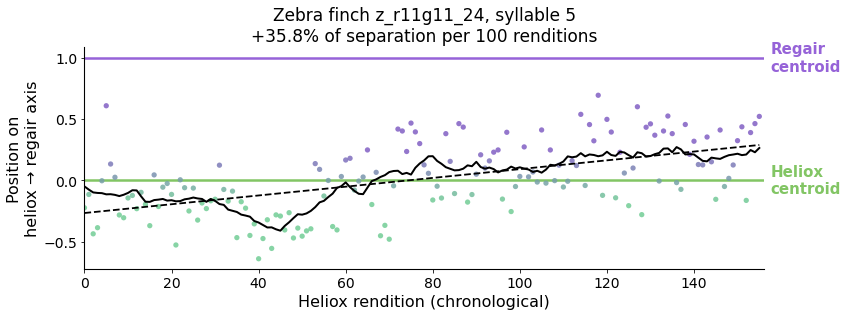

In [3]:
# Cell 2: Fig. 5F
EXAMPLE = 'zf_r11g11_syl5'
Z = T[f'strip_{EXAMPLE}_latents'].filter(like='z').values        # one row per heliox rendition
meta = T[f'strip_{EXAMPLE}_meta'].iloc[0]
c_hx = np.array([meta[f'c_hx{i}'] for i in range(Z.shape[1])], float)
c_reg = np.array([meta[f'c_reg{i}'] for i in range(Z.shape[1])], float)
axis = c_reg - c_hx
proj = (Z - c_hx) @ axis / (axis @ axis)                         # 0 = heliox centroid, 1 = regair centroid
idx = np.arange(len(proj))
fit = stats.linregress(idx, proj)
slope_pct = 100 * 100 * fit.slope                                # % of the separation per 100 renditions
STATS.append(dict(panel='5F', group='zebra finch', quantity='example syllable slope', estimate=slope_pct,
                  n=len(proj), note=f'{Z.shape[1]} latent columns in the table'))

# green at the heliox end, purple at the regair end; contrast stretched around the middle
lo, hi = np.percentile(proj, [2, 98])
shade = np.clip(0.5 + (np.clip((proj - lo) / (hi - lo), 0, 1) - 0.5) * 2.5, 0, 1)
ramp = LinearSegmentedColormap.from_list('hx_reg', [to_rgb('#72cd96'), to_rgb('#815fc4')])

with plt.rc_context({'font.size': 15, 'axes.titlesize': 18, 'axes.labelsize': 16,
                     'xtick.labelsize': 14, 'ytick.labelsize': 14}):
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.scatter(idx, proj, s=28, c=ramp(shade)[:, :3], lw=0, alpha=0.85)
    ax.plot(idx, pd.Series(proj).rolling(15, center=True, min_periods=1).mean(), color='k', lw=2)
    ax.plot(idx, fit.intercept + fit.slope * idx, color='k', ls='--', lw=1.8)
    for y, cond, label in [(0, 'heliox', 'Heliox\ncentroid'), (1, 'regair', 'Regair\ncentroid')]:
        ax.axhline(y, color=CONDITION_COLORS[cond], lw=2.5, zorder=0)
        ax.text(1.01, y, label, transform=ax.get_yaxis_transform(), color=CONDITION_COLORS[cond],
                va='center', ha='left', fontsize=15, fontweight='bold')
    ax.set_xlim(0, len(proj))
    ax.set_xlabel('Heliox rendition (chronological)')
    ax.set_ylabel('Position on\nheliox → regair axis')
    ax.set_title(f'Zebra finch {meta["bird"]}, syllable {meta["label"]}\n'
                 f'{slope_pct:+.1f}% of separation per 100 renditions', fontsize=17)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    for side in ['left', 'bottom']:
        ax.spines[side].set_linewidth(1.1)
    plt.tight_layout()
    save('zf_heliox_to_regair_projection.png')
    plt.show()

## Fig. 5 G-H: the two species side by side

Both panels share one layout: a point and 95% CI per species, stars for each species
against zero, and a bracket for the species comparison.

In [4]:
# Cell 3: the shared two-species panel
PANEL_STYLE = {'font.size': 16, 'axes.titlesize': 19, 'axes.labelsize': 16,
               'xtick.labelsize': 18, 'ytick.labelsize': 16}
SPECIES_GRAY = ['#666666', '#aaaaaa']        # dark = zebra finch, light = starling
AXIS_GRAY = '#808080'


def stars(p):
    return ('****' if p < 1e-4 else '***' if p < 1e-3 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns')


def species_panel(ax, est, half, p_each, p_between, title, title_color, ylabel):
    """est, half, p_each: [zebra finch, starling]. half is the half-width of the 95% CI."""
    est, half = np.asarray(est, float), np.asarray(half, float)
    lo, hi = min((est - half).min(), 0), max((est + half).max(), 0)
    span = hi - lo
    for i in range(2):
        ax.plot([i, i], [est[i] - half[i], est[i] + half[i]], color='k', lw=3, zorder=2, solid_capstyle='butt')
        ax.scatter(i, est[i], s=190, color=SPECIES_GRAY[i], zorder=3, lw=0)
        # stars sit on the side of the CI away from zero
        above = est[i] > 0 and stars(p_each[i]) != 'ns'
        ax.text(i, est[i] + half[i] + 0.04 * span if above else est[i] - half[i] - 0.04 * span,
                stars(p_each[i]), ha='center', va='bottom' if above else 'top',
                fontsize=18 if stars(p_each[i]) != 'ns' else 16)
    ax.axhline(0, color=AXIS_GRAY, ls='--', lw=2, zorder=0)
    y = hi + 0.30 * span
    top = y + 0.08 * span
    ax.plot([0, 0, 1, 1], [y, top, top, y], color='k', lw=2)
    ax.text(0.5, top + 0.01 * span, stars(p_between), ha='center', va='bottom',
            fontsize=18 if stars(p_between) != 'ns' else 16)
    ax.set_ylim(lo - 0.35 * span, top + 0.22 * span)
    ax.set_xlim(-0.5, 1.5)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Zebra\nFinch', 'Starling'])
    ax.tick_params(axis='x', length=0, pad=8)
    ax.tick_params(axis='y', color=AXIS_GRAY, width=1.5)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    for side in ['left', 'bottom']:
        ax.spines[side].set_color(AXIS_GRAY)
        ax.spines[side].set_linewidth(2)
    ax.set_title(title, color=title_color, fontweight='bold', pad=14)
    ax.set_ylabel(ylabel)

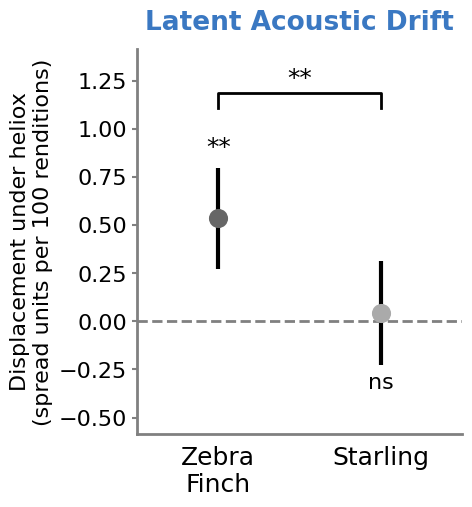

In [5]:
# Cell 4: Fig. 5G, directional drift in latent space
# One value per bird: drift of its syllables beyond what shuffled rendition order gives,
# in units of spread. Each species is tested against zero with a one-sample t-test on bird
# means; the species comparison is the mixed model on syllables (drift ~ species + (1 | bird)).
drift = T['disp_heliox_birds'].set_index(['species', 'bird'])['disp']
species_test = T['disp_heliox_stats'].iloc[0]
window = int(species_test['W'])                                  # renditions per window

est, half, p_each = [], [], []
for sp in SPECIES:
    v = drift.xs(sp).values
    mean, sem = v.mean(), v.std(ddof=1) / np.sqrt(len(v))
    h = sem * stats.t.ppf(0.975, len(v) - 1)
    t, p = stats.ttest_1samp(v, 0)
    est.append(mean); half.append(h); p_each.append(p)
    STATS.append(dict(panel='5G', group=sp, quantity='latent drift', estimate=mean, CI_low=mean - h,
                      CI_high=mean + h, SE=sem, t=t, df=len(v) - 1, P=p, n=len(v)))
STATS.append(dict(panel='5G', group='zebra finch vs starling', quantity='latent drift',
                  estimate=species_test['b'], SE=species_test['se'], t=species_test['t'],
                  df=int(species_test['df']), P=species_test['p'], n=int(species_test['n_cells'])))

with plt.rc_context(PANEL_STYLE):
    fig, ax = plt.subplots(figsize=(4.2, 5))
    species_panel(ax, est, half, p_each, species_test['p'], 'Latent Acoustic Drift', '#3a78c2',
                  f'Displacement under heliox\n(spread units per {window} renditions)')
    save('latent_syllable_displacement_heliox.png')
    plt.show()

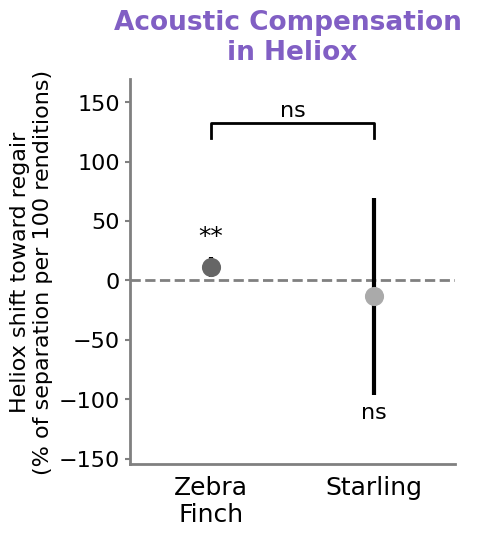

In [6]:
# Cell 5: Fig. 5H, movement toward the regular air centroid
# Pooled slope per species from the intercept-only mixed model on syllables whose two
# centroids are reliably separated. The test against zero is one-sided (movement TOWARD
# regular air); the species comparison is a Wald test on the two pooled estimates.
pooled = {sp: T[f"gap_{sp.replace(' ', '_')}_pooled"].iloc[0] for sp in SPECIES}
pairs = {sp: T[f"gap_{sp.replace(' ', '_')}_pairs"] for sp in SPECIES}

est, half, p_each = [], [], []
for sp in SPECIES:
    g = pooled[sp]
    b, se, df = 100 * g['b'], 100 * g['se'], int(g['df'])       # percent of the centroid separation
    h = stats.t.ppf(0.975, df) * 100 * g['se']
    est.append(b); half.append(h); p_each.append(g['p'])
    STATS.append(dict(panel='5H', group=sp, quantity='movement toward regair (% per 100 renditions)',
                      estimate=b, CI_low=b - h, CI_high=b + h, SE=se, t=g['b'] / g['se'], df=df, P=g['p'],
                      P_two_sided=2 * stats.t.sf(abs(g['b'] / g['se']), df),
                      n=len(pairs[sp]), note=f"{pairs[sp]['bird'].nunique()} birds"))
z = (pooled[SPECIES[0]]['b'] - pooled[SPECIES[1]]['b']) / np.hypot(pooled[SPECIES[0]]['se'], pooled[SPECIES[1]]['se'])
p_between = 2 * stats.norm.sf(abs(z))
STATS.append(dict(panel='5H', group='zebra finch vs starling', quantity='movement toward regair', z=z, P=p_between))

with plt.rc_context(PANEL_STYLE):
    fig, ax = plt.subplots(figsize=(4.2, 5))
    species_panel(ax, est, half, p_each, p_between, 'Acoustic Compensation \nin Heliox', '#815fc4',
                  'Heliox shift toward regair\n(% of separation per 100 renditions)')
    save('heliox_shift_to_regair.png')
    plt.show()